<a href="https://colab.research.google.com/github/sofilukash/dimensionality_reduction_clustering_and_classification_of_text_data/blob/main/PCA_TSNE_KMeans_Text.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практичне заняття 4. Навчання без учителя та обробка текстів
### PCA · t-SNE · K-Means · TF-IDF · WordCloud

---

## Мета роботи

Ознайомитися з базовими методами **навчання без учителя** та **обробки текстових даних**: зниженням розмірності, візуалізацією і кластеризацією даних, а також побудовою базового workflow класифікації текстів з використанням бібліотеки **Scikit-learn**.

## Завдання та структура блокнота

| № | Завдання | Що саме робимо | Розділ у блокноті |
|---|----------|----------------|-------------------|
| 1 | Зниження розмірності та візуалізація | PCA → порівняння якості класифікації «до» і «після»; t-SNE у 2D з розфарбуванням за класами | Розділ 1 |
| 2 | Кластерний аналіз | K-Means без міток, вибір *k* (Elbow + Silhouette), візуалізація у 2D, порівняння кластерів зі справжніми класами | Розділ 2 |
| 3 | Тексти | Передобробка, WordCloud для кожного класу, TF-IDF, класифікатор, метрики якості | Розділ 3 |

**Дані.** Розділи 1–2 — той самий датасет, що й у лабораторній №1: *Secure and Resilient UAV Communication Dataset* (Kaggle, `researchailabs`). Розділ 3 — текстовий корпус **20 Newsgroups** (3 класи; IMDB, як і вимагає умова, не використовується).

## Як запускати

`Runtime → Run all`. Датасет підтягується автоматично через `kagglehub`; якщо Kaggle недоступний — блокнот попросить завантажити CSV вручну. Усі параметри, які можна змінювати, зібрані в **одній клітинці конфігурації** нижче.

## 0. Підготовка середовища

In [1]:
!pip -q install kagglehub wordcloud

In [2]:
import os, glob, time, re, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, silhouette_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score,
                             homogeneity_score, completeness_score)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42                      # фіксуємо випадковість -> результати відтворювані
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
print("Бібліотеки підключено")

Бібліотеки підключено


### Конфігурація

Усі «ручки» експерименту — в одному місці. Значення за замовчуванням підібрані так, щоб блокнот працював за кілька хвилин навіть на великому датасеті.

| Параметр | Сенс |
|----------|------|
| `TARGET_COL` | назва колонки з класом. `None` — блокнот спробує визначити її автоматично (і напише, що обрав) |
| `MAX_ROWS_MAIN` | якщо рядків більше — беремо **стратифіковану** підвибірку (зберігає частки класів) |
| `MAX_ROWS_TSNE` | t-SNE дуже повільний (≈ O(n²)), тому візуалізуємо підвибірку |
| `MAX_CLASSES_CLUSTER` | якщо класів багато — для кластеризації лишаємо 2–3 найчисленніші (дозволено умовою) |
| `K_RANGE` | діапазон кількості кластерів для Elbow / Silhouette |
| `K_CHOSEN` | `None` — *k* обирається за найбільшим Silhouette; можна задати вручну |
| `PCA_VARIANCE` | яку частку дисперсії зберігає основний PCA-експеримент |

In [3]:
KAGGLE_DATASET = "researchailabs/secure-and-resilient-uav-communication-dataset"
CSV_NAME = None            # якщо в датасеті кілька файлів - вкажіть потрібний, напр. "data.csv"
TARGET_COL = None          # None -> автовизначення

MAX_ROWS_MAIN = 50_000
MAX_ROWS_TSNE = 3_000
MAX_ROWS_KMEANS = 20_000
MAX_CLASSES_CLUSTER = 3
K_RANGE = range(2, 11)
K_CHOSEN = None
PCA_VARIANCE = 0.95

## Розділ 0. Дані: завантаження, огляд, підготовка

### Що робимо
1. Завантажуємо датасет (Kaggle → `kagglehub`; запасний варіант — ручне завантаження).
2. Знаходимо колонку з класом (target).
3. Дивимось на розмір таблиці, типи ознак, пропуски, розподіл класів.
4. Готуємо числову матрицю ознак: прибираємо дублікати та «службові» колонки, кодуємо категорії, заповнюємо пропуски.

> Це та сама підготовка, що й у лабораторній №1 — тут вона оформлена функцією, щоб однаково застосовуватись у всіх розділах.

In [4]:
try:
    import kagglehub
    DATA_DIR = kagglehub.dataset_download(KAGGLE_DATASET)
    print("Датасет завантажено в:", DATA_DIR)
except Exception as e:
    print("kagglehub не спрацював:", repr(e)[:200])
    from google.colab import files
    print("Завантажте CSV-файл датасету вручну:")
    files.upload()
    DATA_DIR = "."

found = [p for p in glob.glob(os.path.join(DATA_DIR, "**", "*"), recursive=True)
         if p.lower().endswith((".csv", ".xlsx", ".xls"))]
print("\nЗнайдені файли:")
for p in found:
    print(f"  {os.path.relpath(p, DATA_DIR):60s} {os.path.getsize(p)/1e6:8.2f} МБ")

if CSV_NAME:
    data_path = [p for p in found if os.path.basename(p) == CSV_NAME][0]
else:
    data_path = max(found, key=os.path.getsize)      # за замовчуванням - найбільший файл
print("\nВикористовуємо:", data_path)

df_raw = (pd.read_excel(data_path) if data_path.lower().endswith((".xlsx", ".xls"))
          else pd.read_csv(data_path, low_memory=False))
print("Розмір таблиці:", df_raw.shape)
df_raw.head()

100%|██████████| 683k/683k [00:00<00:00, 24.7MB/s]

Extracting files...
Датасет завантажено в: /root/.cache/kagglehub/datasets/researchailabs/secure-and-resilient-uav-communication-dataset/versions/1

Знайдені файли:
  FANET Disaster Dataset.csv                                       1.53 МБ

Використовуємо: /root/.cache/kagglehub/datasets/researchailabs/secure-and-resilient-uav-communication-dataset/versions/1/FANET Disaster Dataset.csv


Розмір таблиці: (5000, 22)


,UAV_ID,Role,X,Y,Z,Velocity,Direction,Energy_Level,Neighbor_Count,Link_Stability,...,Throughput,Packet_Delivery_Ratio,Signal_Strength,Disaster_Type,Obstacle_Density,Weather_Condition,Attack_Type,Recovery_Time,Route_Change_Count,Network_Status
0,52,Sensor,25.896070,524.585579,231.419533,29.899351,167.173833,38.415590,1,0.624923,...,82.468916,0.955169,-94.312313,Cyclone,0.359033,Smoke,Replay,29.051812,14,Degraded
1,93,Sensor,285.211745,222.748770,68.653310,11.018614,229.804488,65.064156,14,0.460945,...,53.653340,0.636328,-47.406575,Cyclone,0.405394,Windy,Jamming,22.047519,3,Critical
2,15,Sensor,553.969950,337.656169,150.723903,27.511250,316.610347,73.974680,11,0.690067,...,46.723480,0.679186,-92.428641,Earthquake,0.246429,Windy,Sybil,44.297353,14,Critical
3,72,Relay,1.601188,490.350441,50.638397,7.362888,273.693110,10.933315,4,0.477680,...,57.621276,0.925962,-61.124781,Cyclone,0.571353,Windy,NaN,12.903208,13,Degraded
4,61,Sensor,283.219084,316.885552,177.801686,22.745005,327.223118,13.080558,9,0.957999,...,36.329833,0.745412,-76.678259,Earthquake,0.435168,Clear,NaN,16.557381,14,Critical


In [5]:
def detect_target(df):
    """Шукаємо колонку з класом: за типовою назвою, інакше - остання колонка з малою кількістю значень."""
    names = ["label", "labels", "target", "class", "attack", "attack_type", "attack_label",
             "type", "category", "status", "anomaly", "is_attack", "malicious"]
    low = {c.lower().strip().replace(" ", "_"): c for c in df.columns}
    for n in names:
        if n in low:
            return low[n]
    for c in df.columns[::-1]:
        if 2 <= df[c].nunique() <= 20 and not pd.api.types.is_float_dtype(df[c]):
            return c
    raise ValueError("Не вдалося визначити target автоматично - задайте TARGET_COL вручну.")

target = TARGET_COL or detect_target(df_raw)
print(f"Колонка з класом: '{target}'")
print("Якщо це не та колонка - задайте TARGET_COL у конфігурації й перезапустіть.\n")

df_raw.info(max_cols=60)
print("\nПропуски (топ-10):")
print(df_raw.isna().sum().sort_values(ascending=False).head(10))

Колонка з класом: 'Attack_Type'
Якщо це не та колонка - задайте TARGET_COL у конфігурації й перезапустіть.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   UAV_ID                 5000 non-null   int64  
 1   Role                   5000 non-null   object 
 2   X                      5000 non-null   float64
 3   Y                      5000 non-null   float64
 4   Z                      5000 non-null   float64
 5   Velocity               5000 non-null   float64
 6   Direction              5000 non-null   float64
 7   Energy_Level           5000 non-null   float64
 8   Neighbor_Count         5000 non-null   int64  
 9   Link_Stability         5000 non-null   float64
 10  Topology_Change_Rate   5000 non-null   float64
 11  Latency                5000 non-null   float64
 12  Throughput             5000 non-null   float64
 13  

Attack_Type
Blackhole    1037
Jamming      1018
Replay       1016
Sybil         941
Name: count, dtype: int64


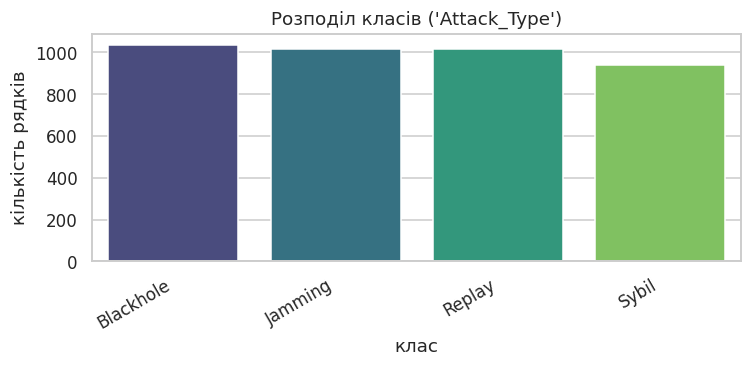

Частка найбільшого класу: 25.8%  ->  класи збалансовані


In [6]:
vc = df_raw[target].value_counts()
print(vc)

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.barplot(x=vc.index.astype(str), y=vc.values, ax=ax, palette="viridis")
ax.set_title(f"Розподіл класів ('{target}')")
ax.set_xlabel("клас"); ax.set_ylabel("кількість рядків")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()
print(f"Частка найбільшого класу: {vc.max()/vc.sum():.1%}  ->  "
      + ("класи збалансовані" if vc.max()/vc.sum() < 0.6 else "є дисбаланс: дивимось не лише на accuracy, а й на F1-macro"))

In [7]:
def prepare(df, target, max_onehot=20):
    """Сирa таблиця -> (X: числові ознаки, y: клас). Друкує, що саме було зроблено."""
    df = df.drop_duplicates().copy()
    df = df[df[target].notna()]
    y = df[target].astype(str)
    X = df.drop(columns=[target])
    log = []

    # 1) порожні та константні колонки не несуть інформації
    const = [c for c in X.columns if X[c].nunique(dropna=True) <= 1]
    X = X.drop(columns=const); log.append(f"константні/порожні колонки: {len(const)}")

    # 2) текстові колонки: мало значень -> one-hot, багато (IP, час, id) -> прибираємо
    obj = X.select_dtypes(include=["object", "category", "string"]).columns
    to_drop = [c for c in obj if X[c].nunique() > max_onehot]
    X = X.drop(columns=to_drop); log.append(f"високо-кардинальні текстові колонки (id, час тощо): {to_drop}")
    to_ohe = [c for c in X.columns if c in obj and c not in to_drop]
    X = pd.get_dummies(X, columns=to_ohe, dtype=float)
    log.append(f"закодовано one-hot: {to_ohe}")

    # 3) логічні -> числа, нескінченності -> NaN, NaN -> медіана
    X = X.apply(pd.to_numeric, errors="coerce").astype(float)
    X = X.replace([np.inf, -np.inf], np.nan)
    n_nan = int(X.isna().sum().sum())
    X = X.fillna(X.median())
    X = X.loc[:, X.nunique() > 1]
    log.append(f"заповнено пропусків медіаною: {n_nan}")
    for line in log: print(" -", line)
    return X, y

X_all, y_all = prepare(df_raw, target)

# класи, у яких зовсім мало прикладів, ламають стратифікацію - прибираємо
small = y_all.value_counts()[lambda s: s < 10].index
if len(small):
    print("Видалено рідкісні класи (<10 рядків):", list(small))
    keep = ~y_all.isin(small); X_all, y_all = X_all[keep], y_all[keep]

def stratified_sample(X, y, n, seed=RANDOM_STATE):
    """Підвибірка n рядків із збереженням часток класів."""
    if len(X) <= n:
        return X, y
    X_s, _, y_s, _ = train_test_split(X, y, train_size=n, stratify=y, random_state=seed)
    return X_s, y_s

X_main, y_main = stratified_sample(X_all, y_all, MAX_ROWS_MAIN)
class_names = sorted(y_main.unique())
print(f"\nПісля підготовки: {X_main.shape[0]} рядків, {X_main.shape[1]} числових ознак, класів: {len(class_names)}")
print("Класи:", class_names)

 - константні/порожні колонки: 0
 - високо-кардинальні текстові колонки (id, час тощо): []
 - закодовано one-hot: ['Role', 'Disaster_Type', 'Weather_Condition', 'Network_Status']
 - заповнено пропусків медіаною: 0

Після підготовки: 4012 рядків, 31 числових ознак, класів: 4
Класи: ['Blackhole', 'Jamming', 'Replay', 'Sybil']


> **Перевірка на «витік» (leakage).** Якщо в таблиці є колонка, що фактично дублює клас (наприклад, текстова назва атаки при бінарному target), модель отримає ~100 % «задарма», а PCA/кластеризація покажуть нереально ідеальну структуру. Якщо результати нижче виглядають підозріло ідеальними — перегляньте `X_main.columns` і приберіть таку колонку.

# Розділ 1. Зниження розмірності та візуалізація

## 1.1 PCA: класифікація «до» та «після»

### Умова
Застосувати `sklearn.decomposition.PCA`, навчити класифікатор з Lab 1 на зменшених даних і порівняти з результатом «до PCA». Висновки: як PCA вплинув на якість; наскільки зменшилась кількість ознак; як змінився час навчання.

### Ідея методу
**PCA (метод головних компонент)** повертає систему координат так, щоб перша нова вісь (PC1) ловила **максимум дисперсії** даних, друга (PC2) — максимум з того, що лишилось, і так далі; осі взаємно ортогональні. Ознаки в даних часто **корельовані** (дублюють одна одну), тому більшість інформації вміщується в кількох перших компонентах — решту можна відкинути з малою втратою.

### Що робимо (етапи)
1. Ділимо дані на **train / test (70/30, стратифіковано)**.
2. **Стандартизуємо** ознаки (`StandardScaler`): PCA чутливий до масштабу — ознака з великими числами «перетягнула б» компоненти на себе. Скейлер і PCA **вчимо лише на train** (інакше — витік інформації з тесту).
3. Дивимось **кумулятивну поясненну дисперсію** → скільки компонент потрібно для 80/90/95/99 %.
4. Навчаємо **Random Forest** (алгоритм із Lab 1) на вихідних даних і на PCA-даних, порівнюємо **Accuracy, F1-macro, час навчання**.
5. Додатково — **kNN** (як приклад алгоритму, чутливого до відстаней).

> **Чому F1-macro, а не лише accuracy:** F1-macro усереднює якість по класах однаково, тому не дає «сховати» провал на рідкісному класі за рахунок великого.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X_main, y_main, test_size=0.3, stratify=y_main, random_state=RANDOM_STATE)

scaler = StandardScaler().fit(X_train)                 # навчаємо ТІЛЬКИ на train
Xtr_s, Xte_s = scaler.transform(X_train), scaler.transform(X_test)
print(f"train: {Xtr_s.shape},  test: {Xte_s.shape}")
print("Частки класів у train/test збігаються (стратифікація):")
print(pd.DataFrame({"train": y_train.value_counts(normalize=True), "test": y_test.value_counts(normalize=True)}).round(3))

train: (2808, 31),  test: (1204, 31)
Частки класів у train/test збігаються (стратифікація):
             train   test
Attack_Type              
Blackhole    0.259  0.258
Jamming      0.254  0.254
Replay       0.253  0.253
Sybil        0.235  0.234


Скільки компонент потрібно для збереження частки дисперсії:
  80%: 20 з 31 ознак
  90%: 23 з 31 ознак
  95%: 25 з 31 ознак
  99%: 26 з 31 ознак


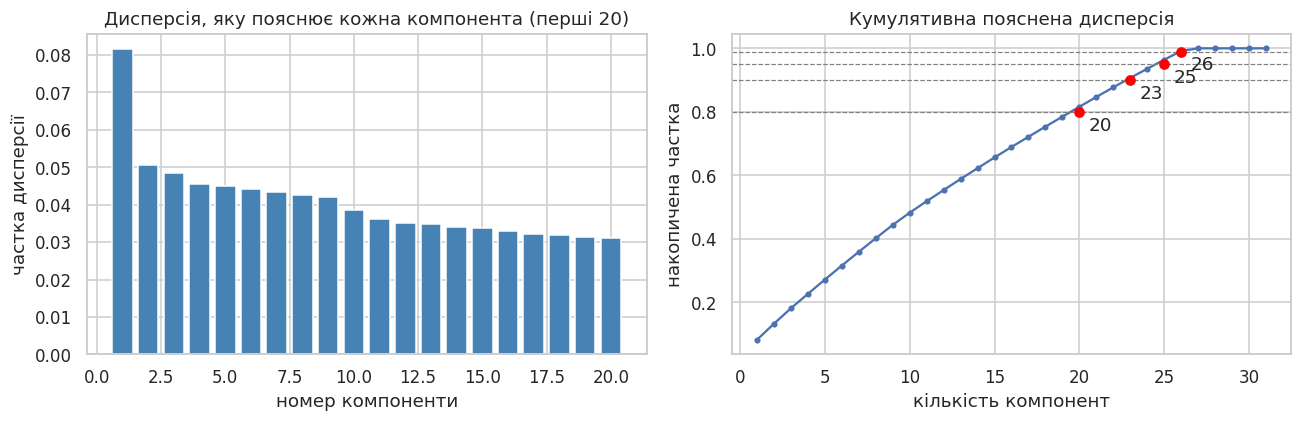

In [9]:
# Повний PCA (усі компоненти) - щоб побачити, як накопичується пояснена дисперсія
pca_full = PCA(random_state=RANDOM_STATE).fit(Xtr_s)
cum = np.cumsum(pca_full.explained_variance_ratio_)
thresholds = [0.80, 0.90, 0.95, 0.99]
n_for = {t: int(np.searchsorted(cum, t) + 1) for t in thresholds}
print("Скільки компонент потрібно для збереження частки дисперсії:")
for t, n in n_for.items():
    print(f"  {t:.0%}: {n} з {Xtr_s.shape[1]} ознак")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
k = min(20, len(cum))
ax[0].bar(range(1, k + 1), pca_full.explained_variance_ratio_[:k], color="steelblue")
ax[0].set_title("Дисперсія, яку пояснює кожна компонента (перші 20)")
ax[0].set_xlabel("номер компоненти"); ax[0].set_ylabel("частка дисперсії")
ax[1].plot(range(1, len(cum) + 1), cum, marker=".")
for t in thresholds:
    ax[1].axhline(t, ls="--", c="gray", lw=0.8)
    ax[1].scatter(n_for[t], t, c="red", zorder=3)
    ax[1].annotate(f"{n_for[t]}", (n_for[t], t), textcoords="offset points", xytext=(6, -12))
ax[1].set_title("Кумулятивна пояснена дисперсія")
ax[1].set_xlabel("кількість компонент"); ax[1].set_ylabel("накопичена частка")
plt.tight_layout(); plt.show()

**Як читати графіки.** Ліворуч — «внесок» кожної компоненти: різке падіння означає, що перші кілька компонент несуть основну інформацію. Праворуч — скільки компонент треба взяти, щоб «набрати» потрібну частку дисперсії; червоні точки — наші пороги. Чим швидше крива виходить на плато, тим сильніше ознаки корельовані й тим більше можна стиснути дані.

In [10]:
def evaluate(model, Xtr, ytr, Xte, yte, repeats=3):
    """Навчає модель (час усереднюється за кілька запусків), повертає метрики й час."""
    fit_times = []
    for _ in range(repeats):
        m = clone(model)
        t0 = time.perf_counter(); m.fit(Xtr, ytr); fit_times.append(time.perf_counter() - t0)
    t0 = time.perf_counter(); pred = m.predict(Xte); t_pred = time.perf_counter() - t0
    return {"Accuracy": accuracy_score(yte, pred),
            "F1-macro": f1_score(yte, pred, average="macro"),
            "Час fit, с": np.mean(fit_times),
            "Час predict, с": t_pred}, m, pred

rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE)

rows, pca_times = {}, {}
res, rf_base, pred_base = evaluate(rf, Xtr_s, y_train, Xte_s, y_test)
rows["Без PCA"] = {"Ознак": Xtr_s.shape[1], **res}

for t in thresholds:
    t0 = time.perf_counter()
    pca = PCA(n_components=t, svd_solver="full", random_state=RANDOM_STATE).fit(Xtr_s)
    Xtr_p, Xte_p = pca.transform(Xtr_s), pca.transform(Xte_s)
    pca_times[t] = time.perf_counter() - t0
    res, _, _ = evaluate(rf, Xtr_p, y_train, Xte_p, y_test)
    rows[f"PCA {t:.0%}"] = {"Ознак": pca.n_components_, **res}

res_df = pd.DataFrame(rows).T
res_df["Ознак"] = res_df["Ознак"].astype(int)
res_df.round(4)

,Ознак,Accuracy,F1-macro,"Час fit, с","Час predict, с"
Без PCA,31,0.2309,0.2283,4.8922,0.1250
PCA 80%,20,0.2176,0.2149,5.6762,0.0649
PCA 90%,23,0.2350,0.2319,3.3619,0.0651
PCA 95%,25,0.2384,0.2355,3.5996,0.0989
PCA 99%,26,0.2375,0.2322,3.7104,0.0647


**Що в таблиці.** Рядок «Без PCA» — еталон. Рядки «PCA 80 % … 99 %» — те саме модель Random Forest, але на компонентах, що зберігають відповідну частку дисперсії. Дивимось на три речі: скільки ознак лишилось, чи просіла якість (Accuracy, F1-macro) і чи змінився час навчання.

ВИСНОВОК (PCA 95%):
 - Кількість ознак: 31 -> 25  (зменшення на 19%).
 - Якість: F1-macro 0.2283 -> 0.2355 (Δ = +0.0073); accuracy 0.2309 -> 0.2384. Якість покращилась.
 - Час навчання RF: 4.89 с -> 3.60 с (скоротився у 1.36 раза). Сам PCA додатково коштує 0.01 с.


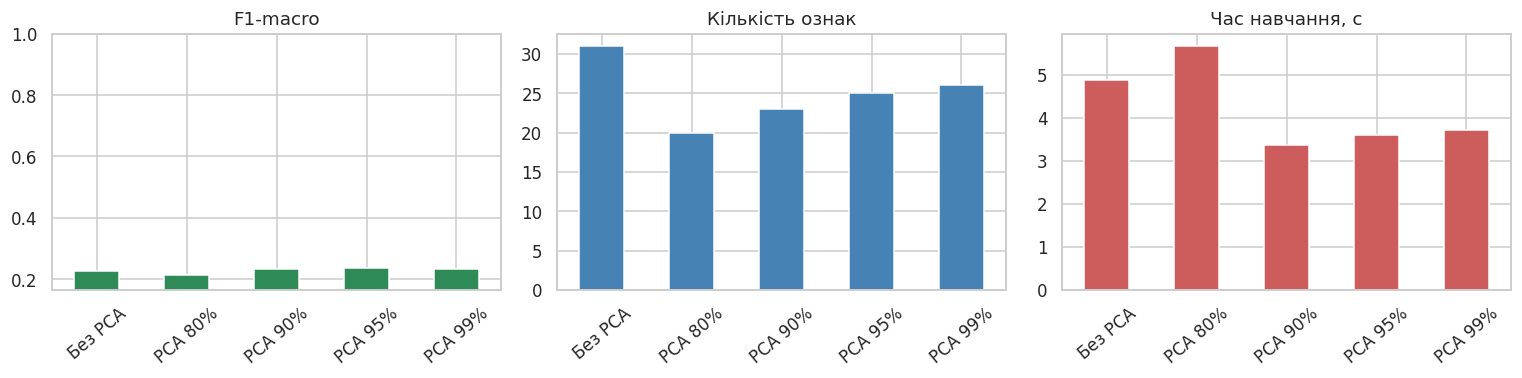

In [11]:
main_key = f"PCA {PCA_VARIANCE:.0%}"
b, p = res_df.loc["Без PCA"], res_df.loc[main_key]

d_f1 = p["F1-macro"] - b["F1-macro"]
red = 1 - p["Ознак"] / b["Ознак"]
ratio = b["Час fit, с"] / p["Час fit, с"]

q = ("практично не змінилась" if abs(d_f1) < 0.005 else
     "покращилась" if d_f1 > 0 else "погіршилась")
tm = (f"скоротився у {ratio:.2f} раза" if ratio > 1.1 else
      f"збільшився у {1/ratio:.2f} раза" if ratio < 0.9 else "майже не змінився")

print(f"ВИСНОВОК ({main_key}):")
print(f" - Кількість ознак: {int(b['Ознак'])} -> {int(p['Ознак'])}  (зменшення на {red:.0%}).")
print(f" - Якість: F1-macro {b['F1-macro']:.4f} -> {p['F1-macro']:.4f} (Δ = {d_f1:+.4f}); "
      f"accuracy {b['Accuracy']:.4f} -> {p['Accuracy']:.4f}. Якість {q}.")
print(f" - Час навчання RF: {b['Час fit, с']:.2f} с -> {p['Час fit, с']:.2f} с ({tm}). "
      f"Сам PCA додатково коштує {pca_times[PCA_VARIANCE]:.2f} с.")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
res_df["F1-macro"].plot.bar(ax=ax[0], color="seagreen"); ax[0].set_title("F1-macro")
ax[0].set_ylim(max(0, res_df["F1-macro"].min() - 0.05), 1.0)
res_df["Ознак"].plot.bar(ax=ax[1], color="steelblue"); ax[1].set_title("Кількість ознак")
res_df["Час fit, с"].plot.bar(ax=ax[2], color="indianred"); ax[2].set_title("Час навчання, с")
for a in ax: a.tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()

### Як інтерпретувати (на що звернути увагу)
- **Якість.** PCA відкидає компоненти з малою дисперсією. Якщо вони були *шумом* або дублювали інші ознаки — якість не падає (інколи трохи росте). Якщо ж *корисний для розрізнення класів* сигнал якраз сидів у «слабких» напрямках — якість просяде. Важливий нюанс: PCA **не знає про класи** (це метод без учителя) — він зберігає дисперсію, а не різницю між класами.
- **Кількість ознак.** Чим сильніше ознаки корельовані, тим сильніше можна стиснути дані без втрат.
- **Час.** Для дерев/лісів кількість ознак напряму впливає на час побудови (на кожному розщепленні перебираються ознаки), тому зменшення ознак зазвичай прискорює навчання. Але на невеликих даних виграш мізерний, а сам PCA додає власні витрати.
- **Інтерпретовність.** Мінус PCA: компоненти — це лінійні комбінації вихідних ознак, і сказати «ця компонента = швидкість польоту» вже не можна.

In [12]:
# Додатково: алгоритм, чутливий до відстаней (kNN), - як PCA впливає на нього
knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
pca_main = PCA(n_components=PCA_VARIANCE, svd_solver="full", random_state=RANDOM_STATE).fit(Xtr_s)
Xtr_p, Xte_p = pca_main.transform(Xtr_s), pca_main.transform(Xte_s)

r1, _, _ = evaluate(knn, Xtr_s, y_train, Xte_s, y_test)
r2, _, _ = evaluate(knn, Xtr_p, y_train, Xte_p, y_test)
pd.DataFrame({"kNN без PCA": {"Ознак": Xtr_s.shape[1], **r1},
              f"kNN + {main_key}": {"Ознак": pca_main.n_components_, **r2}}).T.round(4)

,Ознак,Accuracy,F1-macro,"Час fit, с","Час predict, с"
kNN без PCA,31.0,0.2417,0.2329,0.0104,0.1122
kNN + PCA 95%,25.0,0.2259,0.2171,0.0025,0.0199


**Навіщо цей експеримент.** kNN рахує відстані між об’єктами, і час **передбачення** прямо залежить від кількості ознак — тут ефект PCA на швидкодію зазвичай помітніший, ніж у лісу. Це корисна ілюстрація того, що вплив PCA залежить від типу моделі.

## 1.2 t-SNE: візуалізація даних у 2D

### Умова
Застосувати `sklearn.manifold.TSNE` для зниження розмірності до 2D, візуалізувати з кольорами класів і пояснити результат.

### Ідея методу
**t-SNE** будує 2D-карту так, щоб **близькі в багатовимірному просторі об’єкти лишались близькими на картинці**. Він не лінійний (на відміну від PCA) і добре показує **локальну** структуру — «острівці» схожих об’єктів. Головний параметр — **perplexity** (≈ скільки сусідів враховується для кожної точки; типово 5–50).

### Що робимо
1. Беремо **стратифіковану підвибірку** (t-SNE повільний).
2. Стандартизуємо; якщо ознак > 50 — спершу стискаємо PCA до 50 компонент (стандартна практика: прискорює й прибирає шум).
3. Запускаємо t-SNE, малюємо **поруч із PCA-2D** — для порівняння лінійного й нелінійного підходів.
4. Перевіряємо, як картинка залежить від perplexity (5 / 30 / 50).

Підвибірка для візуалізації: (3000, 31)
t-SNE виконано за 27.8 с


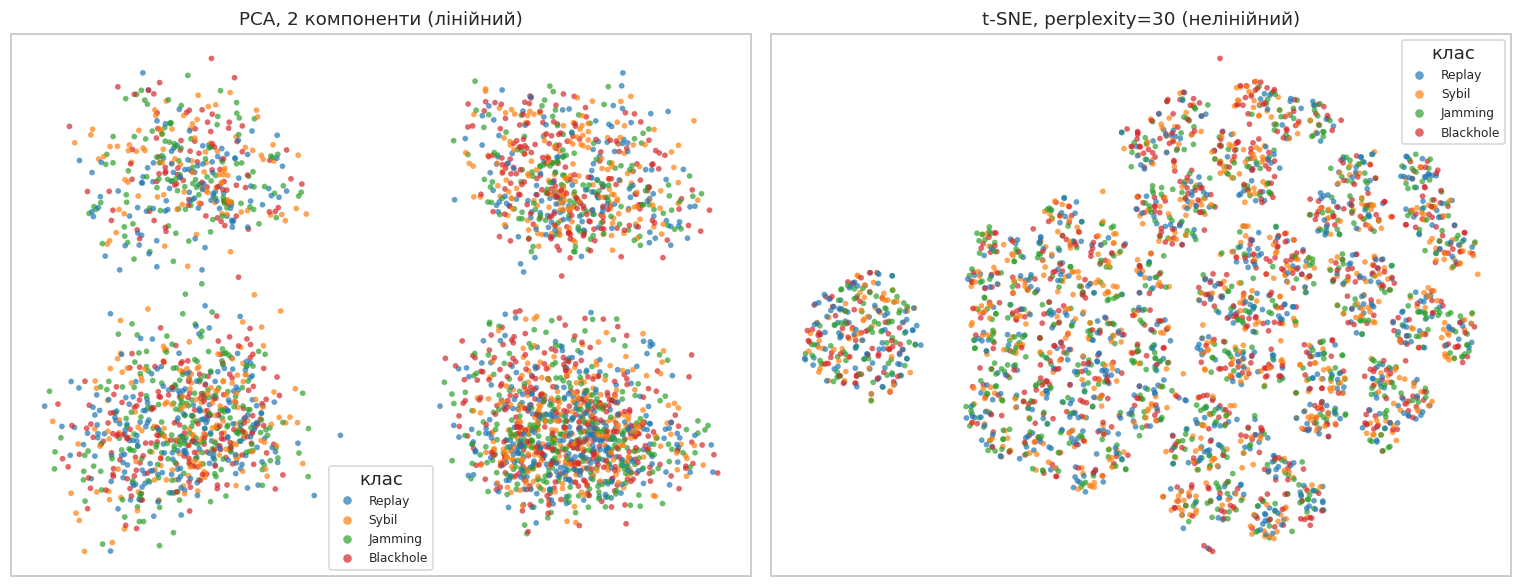

2 компоненти PCA пояснюють лише 13.2% дисперсії.


In [13]:
X_vis, y_vis = stratified_sample(X_all, y_all, MAX_ROWS_TSNE)
Xv = StandardScaler().fit_transform(X_vis)
print("Підвибірка для візуалізації:", Xv.shape)

def run_tsne(Xs, perplexity=30):
    Z = PCA(n_components=50, random_state=RANDOM_STATE).fit_transform(Xs) if Xs.shape[1] > 50 else Xs
    return TSNE(n_components=2, perplexity=perplexity, init="pca", learning_rate="auto",
                random_state=RANDOM_STATE).fit_transform(Z)

t0 = time.perf_counter()
emb_tsne = run_tsne(Xv, 30)
print(f"t-SNE виконано за {time.perf_counter()-t0:.1f} с")
emb_pca = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Xv)

def scatter2d(ax, emb, labels, title):
    sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=np.asarray(labels), s=14, alpha=0.7,
                    palette="tab10", ax=ax, linewidth=0)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
    ax.legend(title="клас", fontsize=8, markerscale=1.5)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
scatter2d(ax[0], emb_pca, y_vis, "PCA, 2 компоненти (лінійний)")
scatter2d(ax[1], emb_tsne, y_vis, "t-SNE, perplexity=30 (нелінійний)")
plt.tight_layout(); plt.show()
print(f"2 компоненти PCA пояснюють лише {PCA(n_components=2).fit(Xv).explained_variance_ratio_.sum():.1%} дисперсії.")

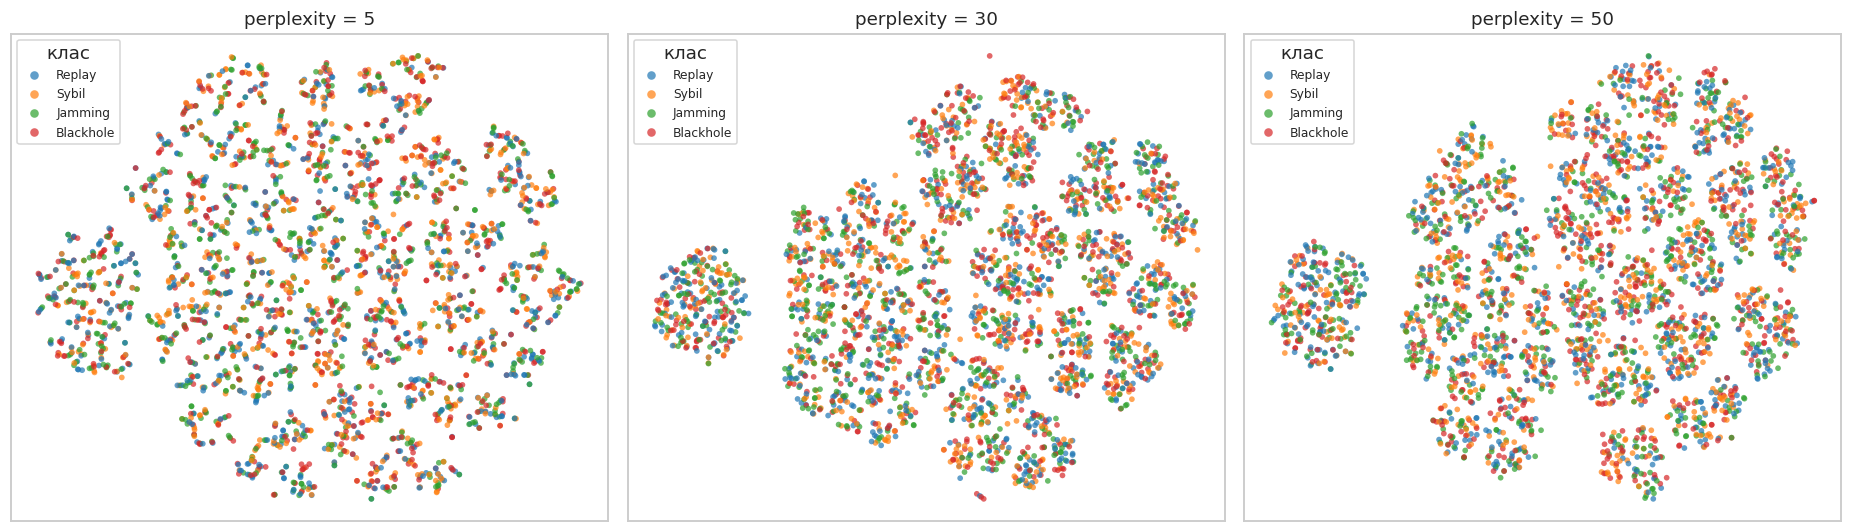

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a, perp in zip(ax, [5, 30, 50]):
    scatter2d(a, run_tsne(Xv, perp), y_vis, f"perplexity = {perp}")
plt.tight_layout(); plt.show()

### Пояснення результату t-SNE (орієнтир для висновків)
- **Що бачимо.** Якщо точки одного кольору збираються в окремі «острівці» — класи в просторі ознак **розділимі**, і класифікатор матиме шанс на високу якість. Якщо кольори змішані — ознаки погано розрізняють класи (або класи за своєю природою перетинаються).
- **PCA vs t-SNE.** PCA в 2D показує лише ту частину структури, яку вмістили дві перші компоненти (процент — друкується вище), тому класи там часто накладаються. t-SNE «розгортає» нелінійну структуру й зазвичай дає чіткіші кластери.
- **Чого НЕ можна робити з t-SNE:** робити висновки з **відстаней між** островами та з їхніх **розмірів** — вони на карті не мають кількісного змісту; змінюється perplexity — змінюється й вигляд карти (див. три панелі). Це інструмент **візуального дослідження**, а не метрика якості.
- **Зв’язок із класифікацією.** Картинка узгоджується з метриками з п. 1.1: чіткі острівці ↔ висока якість класифікатора.

# Розділ 2. Кластерний аналіз (K-Means)

### Умова
Кластеризувати дані **без використання міток класів**; визначити кількість кластерів (Elbow та/або Silhouette); візуалізувати у 2D; порівняти кластери зі справжніми класами; зробити висновок. Пам’ятати: **кластер ≠ клас**.

### Ідея методу
**K-Means** ділить дані на *k* груп так, щоб сума квадратів відстаней від точок до центру *своєї* групи (**inertia**) була мінімальною. Алгоритм ітеративно: (1) призначає кожну точку найближчому центру, (2) перераховує центри як середні. Метод припускає **компактні, приблизно кулясті** кластери й чутливий до масштабу ознак (тому стандартизуємо).

### Як обираємо *k*
- **Elbow (метод ліктя):** будуємо inertia(k). Вона завжди зменшується зі зростанням *k*; шукаємо «лікоть» — точку, після якої виграш різко сповільнюється.
- **Silhouette:** для кожної точки порівнює середню відстань до *своїх* (a) та до *найближчого чужого* кластера (b): s = (b − a) / max(a, b) ∈ [−1; 1]. Чим ближче до 1 — тим чіткіше розділені кластери. Обираємо *k* з максимальним середнім silhouette.
- Додатково — **Davies–Bouldin** (чим менше, тим краще).

### Що робимо
1. Якщо класів > 3 — лишаємо 2–3 найчисленніші (обґрунтування нижче).
2. Масштабуємо ознаки, **прибираємо target** з матриці.
3. Для *k* = 2…10 рахуємо inertia, silhouette, Davies–Bouldin.
4. Обираємо *k*, виконуємо кластеризацію, візуалізуємо PCA-2D і t-SNE-2D (розфарбовуючи **і кластерами, і справжніми класами**).
5. Порівнюємо кластери з класами: таблиця спряженості, ARI, NMI, homogeneity, completeness.

In [15]:
# 1) вибір класів (якщо їх багато)
cls_counts = y_all.value_counts()
if len(cls_counts) > MAX_CLASSES_CLUSTER:
    chosen = list(cls_counts.index[:MAX_CLASSES_CLUSTER])
    print(f"Класів {len(cls_counts)} > {MAX_CLASSES_CLUSTER}. Лишаємо найчисленніші: {chosen}")
    print("Обґрунтування: у рідкісних класів замало прикладів для стійкої кластерної структури, "
          "а три найбільші класи покривають основну частину даних.")
else:
    chosen = list(cls_counts.index)
    print(f"Класів {len(chosen)} - залишаємо всі: {chosen}")

mask = y_all.isin(chosen)
X_c, y_c = stratified_sample(X_all[mask], y_all[mask], MAX_ROWS_KMEANS)
feature_names = list(X_c.columns)

# 2) масштабування; мітки y_c НЕ потрапляють у X (тільки для порівняння наприкінці)
Xc = StandardScaler().fit_transform(X_c)
y_true = LabelEncoder().fit_transform(y_c)
print(f"\nМатриця для кластеризації: {Xc.shape}; розподіл класів:\n{y_c.value_counts().to_string()}")

Класів 4 > 3. Лишаємо найчисленніші: ['Blackhole', 'Jamming', 'Replay']
Обґрунтування: у рідкісних класів замало прикладів для стійкої кластерної структури, а три найбільші класи покривають основну частину даних.

Матриця для кластеризації: (3071, 31); розподіл класів:
Attack_Type
Blackhole    1037
Jamming      1018
Replay       1016


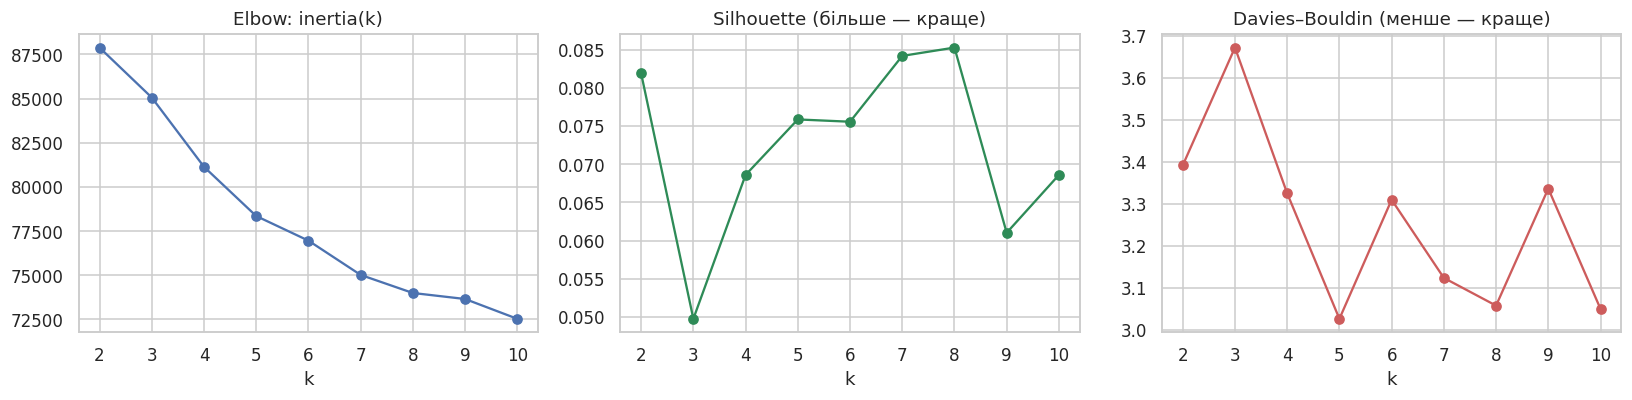

Найбільший silhouette: k = 8 (0.085).  Обрано k = 8.


,inertia,silhouette,davies_bouldin
k,,,
2,87881.575,0.082,3.392
3,85056.860,0.050,3.672
4,81138.033,0.069,3.325
5,78353.090,0.076,3.026
6,76961.328,0.076,3.310
7,75022.159,0.084,3.124
8,73999.378,0.085,3.058
9,73659.763,0.061,3.336
10,72538.772,0.069,3.050


In [16]:
sil_sample = min(5000, len(Xc))            # silhouette рахується за O(n^2) -> на підвибірці
records, labels_by_k = [], {}
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xc)
    labels_by_k[k] = km.labels_
    records.append({"k": k, "inertia": km.inertia_,
                    "silhouette": silhouette_score(Xc, km.labels_, sample_size=sil_sample, random_state=RANDOM_STATE),
                    "davies_bouldin": davies_bouldin_score(Xc, km.labels_)})
k_df = pd.DataFrame(records).set_index("k")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(k_df.index, k_df["inertia"], marker="o"); ax[0].set_title("Elbow: inertia(k)")
ax[1].plot(k_df.index, k_df["silhouette"], marker="o", c="seagreen"); ax[1].set_title("Silhouette (більше — краще)")
ax[2].plot(k_df.index, k_df["davies_bouldin"], marker="o", c="indianred"); ax[2].set_title("Davies–Bouldin (менше — краще)")
for a in ax: a.set_xlabel("k"); a.set_xticks(list(k_df.index))
plt.tight_layout(); plt.show()

k_best = int(k_df["silhouette"].idxmax())
K_FINAL = K_CHOSEN or k_best
print(f"Найбільший silhouette: k = {k_best} ({k_df.loc[k_best, 'silhouette']:.3f}).  Обрано k = {K_FINAL}.")
k_df.round(3)

**Як читати.** Elbow: шукаємо місце, де лінія «перегинається» (далі кожен новий кластер дає дедалі менший виграш) — це суб’єктивний критерій. Silhouette дає числовий вибір (максимум). Якщо критерії **не збігаються** — це нормально, і вибір *k* треба обґрунтувати (наприклад, пріоритет — Silhouette + змістовна інтерпретація). Якщо silhouette низький для всіх *k* (< 0.25), природної кластерної структури в даних, найімовірніше, немає або вона не кулеподібна.

Розміри кластерів: {0: 495, 1: 300, 2: 467, 3: 455, 4: 214, 5: 473, 6: 230, 7: 437}


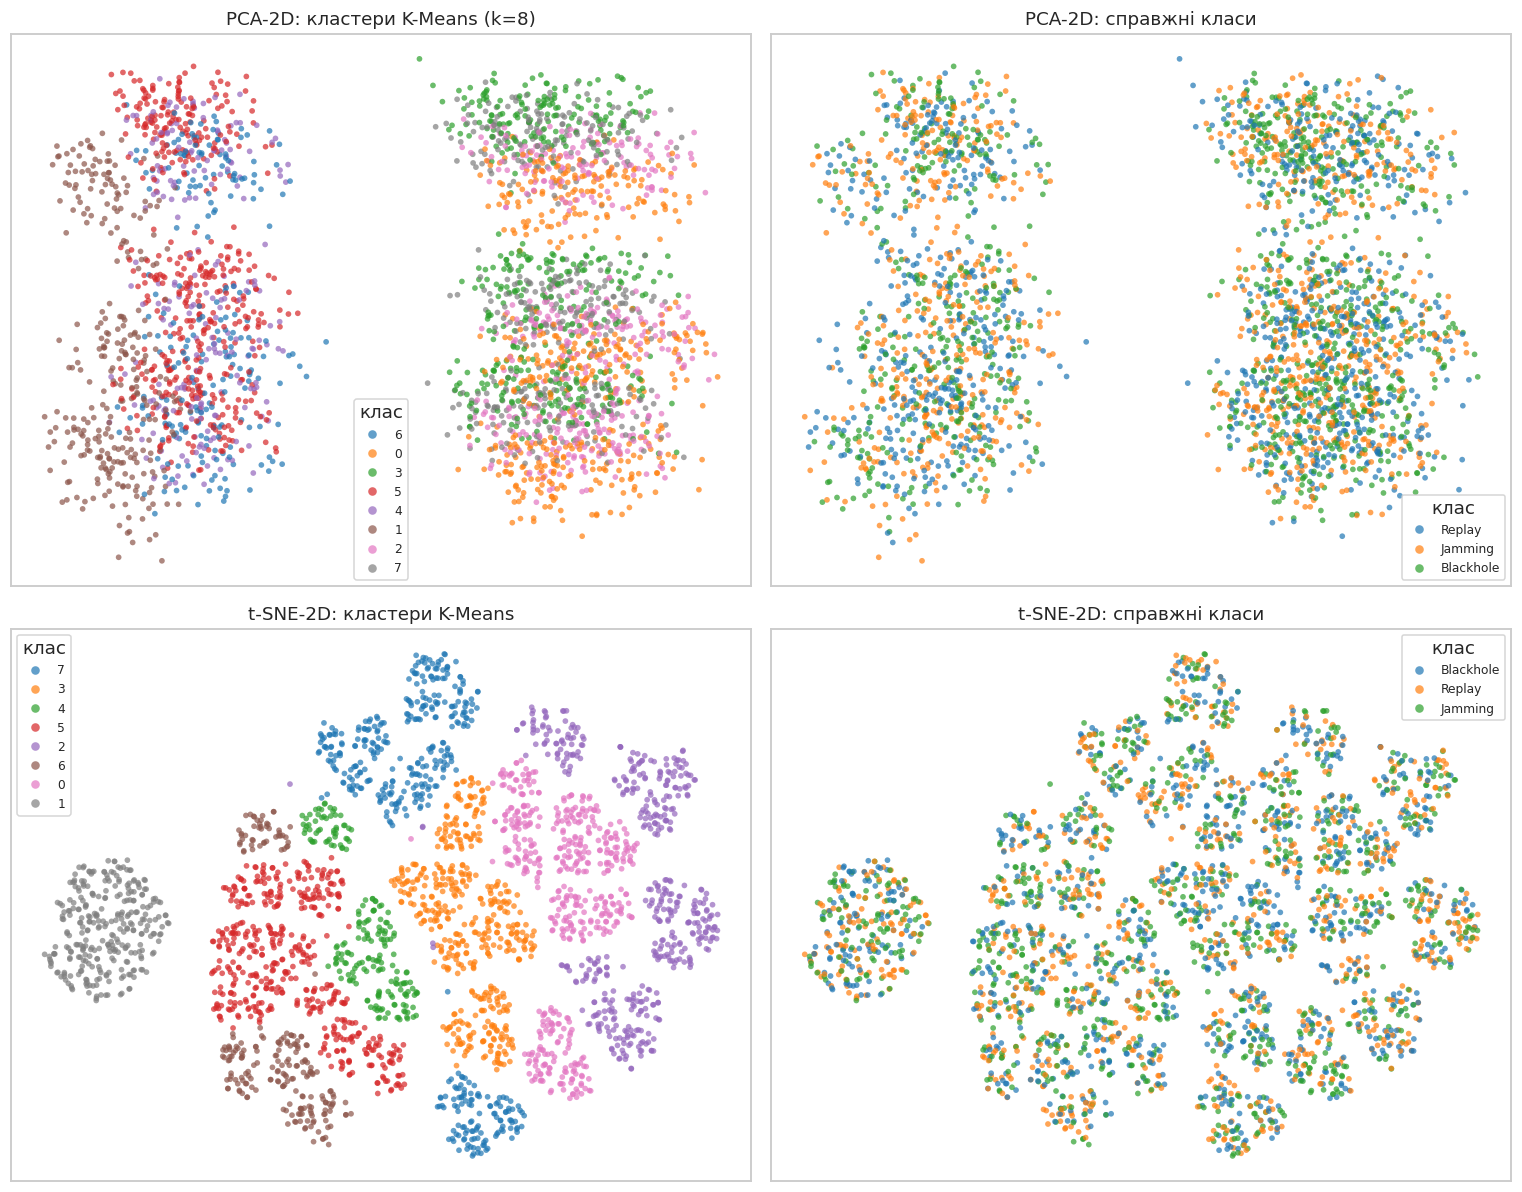

In [17]:
km_final = KMeans(n_clusters=K_FINAL, n_init=10, random_state=RANDOM_STATE).fit(Xc)
clusters = km_final.labels_
print("Розміри кластерів:", {int(k): int(v) for k, v in zip(*np.unique(clusters, return_counts=True))})

# 2D-проєкції: PCA на всій матриці, t-SNE на підвибірці
emb2_pca = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Xc)
idx = np.random.RandomState(RANDOM_STATE).choice(len(Xc), size=min(MAX_ROWS_TSNE, len(Xc)), replace=False)
emb2_tsne = run_tsne(Xc[idx], 30)

true_lab = y_c.values
fig, ax = plt.subplots(2, 2, figsize=(14, 11))
scatter2d(ax[0, 0], emb2_pca, clusters.astype(str), f"PCA-2D: кластери K-Means (k={K_FINAL})")
scatter2d(ax[0, 1], emb2_pca, true_lab, "PCA-2D: справжні класи")
scatter2d(ax[1, 0], emb2_tsne, clusters[idx].astype(str), "t-SNE-2D: кластери K-Means")
scatter2d(ax[1, 1], emb2_tsne, true_lab[idx], "t-SNE-2D: справжні класи")
plt.tight_layout(); plt.show()

**Що порівнюємо на малюнку.** Ліва колонка — як розбив дані K-Means (він «не бачив» міток), права — справжні класи на тих самих координатах. Збіг «кольорових плям» ліворуч і праворуч означає, що знайдена структура відповідає класам; розбіжність — що кластери групують дані за іншою ознакою (наприклад, за режимом роботи, а не за типом події).

Таблиця спряженості (рядки - кластери, стовпці - справжні класи):


клас,Blackhole,Jamming,Replay
кластер,,,
0,173,159,163
1,96,98,106
2,160,138,169
3,181,151,123
4,63,83,68
5,138,176,159
6,83,67,80
7,143,146,148


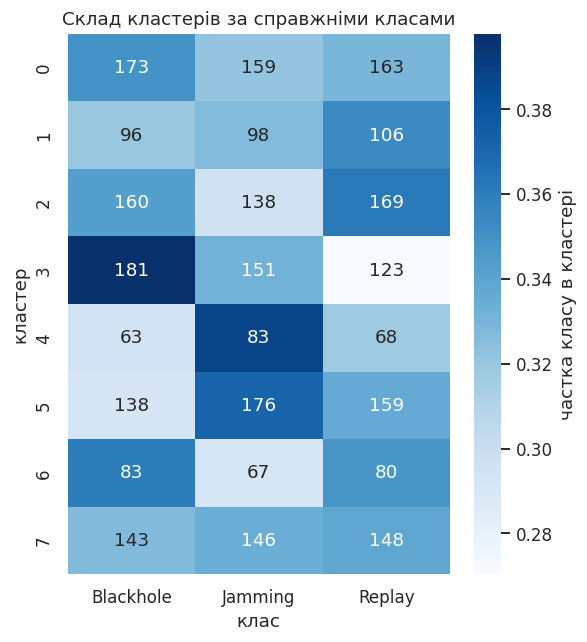

ARI             0.001
NMI             0.003
Homogeneity     0.004
Completeness    0.002
Purity          0.364


In [18]:
ct = pd.crosstab(pd.Series(clusters, name="кластер"), pd.Series(true_lab, name="клас"))
print("Таблиця спряженості (рядки - кластери, стовпці - справжні класи):")
display(ct)

fig, ax = plt.subplots(figsize=(1.6 + 1.3 * ct.shape[1], 1.2 + 0.6 * ct.shape[0]))
sns.heatmap(ct.div(ct.sum(axis=1), axis=0), annot=ct, fmt="d", cmap="Blues", cbar_kws={"label": "частка класу в кластері"}, ax=ax)
ax.set_title("Склад кластерів за справжніми класами"); plt.tight_layout(); plt.show()

ari = adjusted_rand_score(y_true, clusters)
nmi = normalized_mutual_info_score(y_true, clusters)
hom = homogeneity_score(y_true, clusters)
com = completeness_score(y_true, clusters)
purity = ct.max(axis=1).sum() / ct.values.sum()
print(pd.Series({"ARI": ari, "NMI": nmi, "Homogeneity": hom, "Completeness": com, "Purity": purity}).round(3).to_string())

### Метрики порівняння кластерів із класами
| Метрика | Що означає | Діапазон |
|---------|-----------|----------|
| **ARI** (Adjusted Rand Index) | наскільки збігаються два розбиття, з поправкою на випадковий збіг; 0 ≈ випадково | −1…1 |
| **NMI** | скільки інформації про клас дає номер кластера | 0…1 |
| **Homogeneity** | у кожному кластері переважно **один** клас? | 0…1 |
| **Completeness** | кожен клас потрапив переважно в **один** кластер? | 0…1 |
| **Purity** | частка об’єктів, що належать до «головного» класу свого кластера | 0…1 |

Homogeneity і completeness корисні разом: *k* більше за кількість класів зазвичай дає високу homogeneity, але низьку completeness (клас «розмазаний» по кількох кластерах).

In [19]:
# Як зміниться збіг із класами, якщо брати інші k (зокрема k = кількість класів)
n_cls = len(np.unique(y_true))
cmp_df = pd.DataFrame({
    "silhouette": k_df["silhouette"],
    "ARI": {k: adjusted_rand_score(y_true, l) for k, l in labels_by_k.items()},
    "NMI": {k: normalized_mutual_info_score(y_true, l) for k, l in labels_by_k.items()},
}).round(3)
cmp_df.index.name = "k"
print(f"Справжня кількість класів у вибірці: {n_cls}")
cmp_df

Справжня кількість класів у вибірці: 3


,silhouette,ARI,NMI
k,,,
2,0.082,0.001,0.001
3,0.050,0.001,0.001
4,0.069,0.000,0.001
5,0.076,0.000,0.001
6,0.076,0.000,0.002
7,0.084,0.001,0.002
8,0.085,0.001,0.003
9,0.061,0.000,0.002
10,0.069,0.000,0.002


In [20]:
# Чим кластери відрізняються між собою: ознаки з найбільшим відхиленням центру від загального середнього (у z-оцінках)
centers = pd.DataFrame(km_final.cluster_centers_, columns=feature_names)
for c in centers.index:
    top = centers.loc[c].abs().sort_values(ascending=False).head(4).index
    desc = ", ".join(f"{f} ({centers.loc[c, f]:+.1f}σ)" for f in top)
    print(f"Кластер {c} (n={int((clusters==c).sum())}): {desc}")

print("\n" + "=" * 70)
level = ("слабкий" if ari < 0.1 else "частковий" if ari < 0.5 else "сильний")
print(f"ВИСНОВОК: k={K_FINAL} (найкращий silhouette = {k_df.loc[K_FINAL, 'silhouette']:.3f}), "
      f"справжніх класів — {n_cls}.")
print(f"ARI = {ari:.3f}, NMI = {nmi:.3f} -> збіг кластерів із класами {level}.")
if k_df.loc[K_FINAL, "silhouette"] < 0.25:
    print("Silhouette низький: кластерна структура слабко виражена / не кулеподібна.")

Кластер 0 (n=495): Disaster_Type_Cyclone (+1.7σ), Network_Status_Critical (+0.8σ), Network_Status_Degraded (-0.7σ), Disaster_Type_Earthquake (-0.6σ)
Кластер 1 (n=300): Network_Status_Normal (+3.0σ), Network_Status_Critical (-1.2σ), Latency (-1.2σ), Packet_Delivery_Ratio (+1.2σ)
Кластер 2 (n=467): Disaster_Type_Flood (+1.8σ), Network_Status_Critical (+0.8σ), Network_Status_Degraded (-0.7σ), Disaster_Type_Cyclone (-0.6σ)
Кластер 3 (n=455): Disaster_Type_Earthquake (+1.7σ), Network_Status_Critical (+0.8σ), Network_Status_Degraded (-0.7σ), Disaster_Type_Cyclone (-0.6σ)
Кластер 4 (n=214): Weather_Condition_Windy (+1.8σ), Network_Status_Degraded (+1.5σ), Network_Status_Critical (-1.2σ), Weather_Condition_Smoke (-0.6σ)
Кластер 5 (n=473): Network_Status_Degraded (+1.5σ), Network_Status_Critical (-1.2σ), Weather_Condition_Clear (+0.7σ), Weather_Condition_Smoke (-0.6σ)
Кластер 6 (n=230): Weather_Condition_Smoke (+1.7σ), Network_Status_Degraded (+1.5σ), Network_Status_Critical (-1.2σ), Weather_Co

### Пояснення результату (орієнтир для висновків)
- **Кластер ≠ клас.** Клас — це *мітка, яку людина присвоїла* (наприклад, «атака»/«норма»); кластер — це *група об’єктів, схожих за ознаками*. K-Means не знає про мітки й шукає лише геометричну компактність. Збіг означає, що клас **геометрично відокремлений** в просторі ознак; розбіжність — що ознаки групують дані за іншим принципом (режим, умови, масштаб значень) або що клас має складну форму, яку K-Means (кулясті кластери) не вловлює.
- **Чому оптимальне *k* може не дорівнювати кількості класів.** Один клас може складатися з кількох підгруп (різні режими), або кілька класів можуть бути неподільно змішані. Таблиця «*k* → ARI/NMI» вище це показує.
- **Практичний сенс для кібербезпеки.** Кластеризацію можна використовувати як **розвідувальний** інструмент: знайти підгрупи трафіку, виявити малі кластери-«аномалії». Але як готовий класифікатор вона не годиться, якщо ARI низький — для цього є моделі з учителем (Розділ 1).

# Розділ 3. Обробка та класифікація текстових даних

### Умова
Завантажити набір текстів із мітками класів; виконати передобробку (стоп-слова, пунктуація); побудувати **WordCloud** для кожного класу та пояснити; векторизувати (`TfidfVectorizer`); навчити модель і оцінити метриками. IMDB не обирати; якщо класів багато — достатньо 2–3.

### Вибір даних
**20 Newsgroups** (`sklearn.datasets.fetch_20newsgroups`) — класичний корпус новинних груп. Беремо **3 класи** з тематичної групи `sci`:

| Клас | Тема |
|------|------|
| `sci.crypt` | криптографія (близько до профілю нашого курсу — інформаційна безпека) |
| `sci.med` | медицина |
| `sci.space` | космос |

Три класи достатньо різні за лексикою, щоб WordCloud був показовим, але всі з однієї «наукової» групи — тож задача не тривіальна. Завантаження через `sklearn` — без ручного скачування файлів.

### Що робимо
1. Завантажуємо train/test (**офіційний поділ** корпусу). Прибираємо заголовки, підписи та цитати (`remove=("headers","footers","quotes")`) — інакше модель «підгляне» мітку у службовому тексті (наприклад, назва групи в заголовку листа) і результат буде завищений.
2. Передобробка: нижній регістр → видалення посилань/email → видалення пунктуації та цифр → видалення стоп-слів та коротких токенів.
3. WordCloud по класах (окремо для слів і для словосполучень).
4. TF-IDF → класифікатор → метрики.

In [21]:
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from wordcloud import WordCloud

CATS = ["sci.crypt", "sci.med", "sci.space"]
REMOVE = ("headers", "footers", "quotes")
news_tr = fetch_20newsgroups(subset="train", categories=CATS, remove=REMOVE, random_state=RANDOM_STATE)
news_te = fetch_20newsgroups(subset="test", categories=CATS, remove=REMOVE, random_state=RANDOM_STATE)

cls_txt = news_tr.target_names
print("Класи:", cls_txt)
print("train:", len(news_tr.data), " test:", len(news_te.data))
print("\nРозподіл у train:", dict(zip(cls_txt, np.bincount(news_tr.target))))
print("\n--- приклад сирого тексту (клас:", cls_txt[news_tr.target[0]], ") ---")
print(news_tr.data[0][:500])

Класи: ['sci.crypt', 'sci.med', 'sci.space']
train: 1782  test: 1186

Розподіл у train: {'sci.crypt': np.int64(595), 'sci.med': np.int64(594), 'sci.space': np.int64(593)}

--- приклад сирого тексту (клас: sci.crypt ) ---
From: "dan mckinnon" <dan.mckinnon@canrem.com>

	   I have lurked here a bit lately, and though some of the math is
	unknown to me, found it interesting. I thought I would post an article I
	found in the Saturday, April 17, 1993 Toronto Star:

	                  'CLIPPER CHIP' to protect privacy

Politics is of course Dirty Pool, old man, and here we have a classic
example: the NSA and the administration have been working on this for
a *long* time, and in parallel with the announcement to us tec


In [22]:
STOP = set(ENGLISH_STOP_WORDS)

def clean_text(text):
    t = text.lower()
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)      # посилання
    t = re.sub(r"\S+@\S+", " ", t)                    # email
    t = re.sub(r"[^a-z\s]", " ", t)                   # пунктуація, цифри, спецсимволи
    return " ".join(w for w in t.split() if len(w) > 2 and w not in STOP)

print("ДО :", news_tr.data[0][:300].replace("\n", " "))
print("\nПІСЛЯ:", clean_text(news_tr.data[0])[:300])

def build(data, target):
    cleaned = [clean_text(t) for t in data]
    keep = [i for i, c in enumerate(cleaned) if len(c.split()) >= 3]       # відкидаємо порожні після очищення
    return [cleaned[i] for i in keep], np.asarray(target)[keep]

Xtxt_tr, ytxt_tr = build(news_tr.data, news_tr.target)
Xtxt_te, ytxt_te = build(news_te.data, news_te.target)
print(f"\nПісля очищення: train {len(Xtxt_tr)}, test {len(Xtxt_te)} документів")

ДО : From: "dan mckinnon" <dan.mckinnon@canrem.com>  	   I have lurked here a bit lately, and though some of the math is 	unknown to me, found it interesting. I thought I would post an article I 	found in the Saturday, April 17, 1993 Toronto Star:  	                  'CLIPPER CHIP' to protect privacy  Po

ПІСЛЯ: dan mckinnon lurked bit lately math unknown interesting thought post article saturday april toronto star clipper chip protect privacy politics course dirty pool old man classic example nsa administration working long time parallel announcement techies hitting press propoganda bet big magazines byte 

Після очищення: train 1723, test 1123 документів


**Що зробила передобробка.** Лишились лише змістовні слова: без розділових знаків, цифр, службових слів («the», «and», «with»…) та технічного сміття (посилання, адреси). Це зменшує шум і розмір словника. *Примітка:* лематизацію/стемінг не застосовуємо навмисно — TF-IDF із логістичною регресією на цьому корпусі працює добре і без неї, а код лишається простим.

## 3.1 WordCloud: характерні слова та словосполучення

**Як визначаємо «характерність».** Просто частота слів дає хмару загальних слів («people», «like», «know»), однакових для всіх класів. Тому використовуємо **середню TF-IDF вагу** слова в документах класу, а слова, що трапляються у >50 % документів (`max_df=0.5`), відкидаємо: TF-IDF підсилює слова, які **часті в документі, але рідкісні в корпусі**, тобто саме ті, що відрізняють клас. Розмір слова на хмарі ∝ його середній вазі.

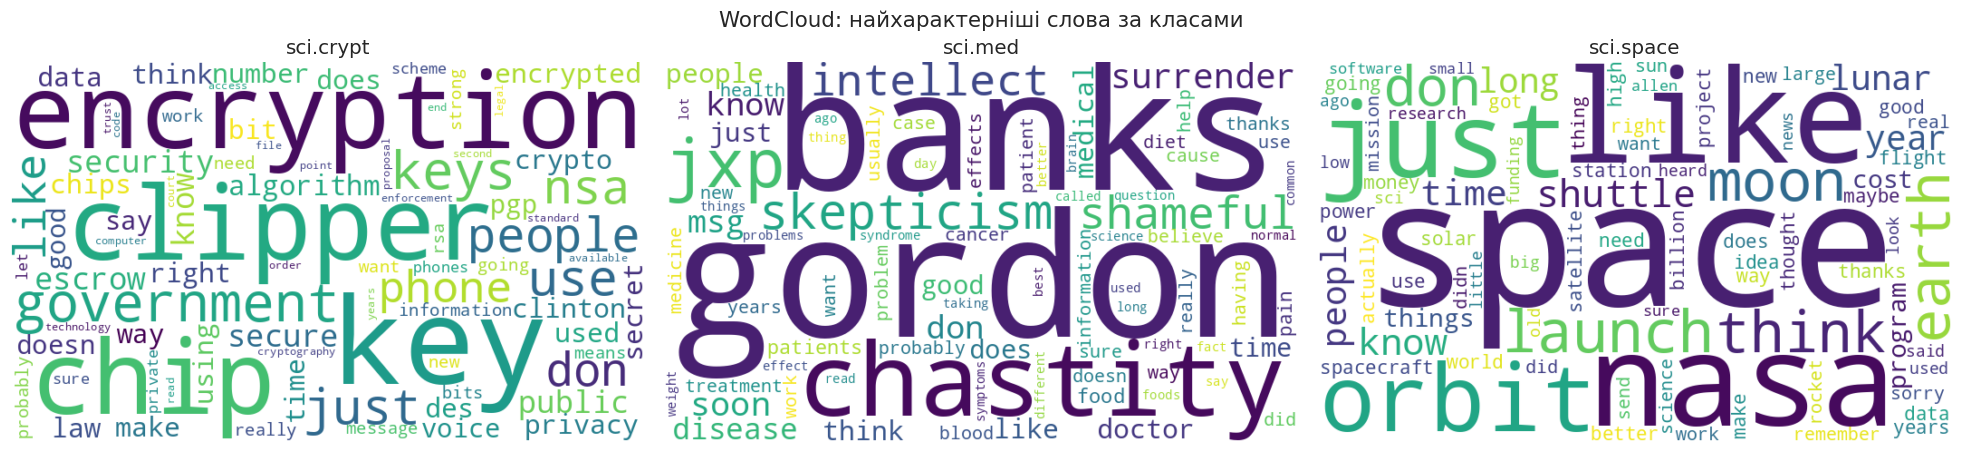

Топ-10 слів за середньою TF-IDF вагою:


,sci.crypt,sci.med,sci.space
1,key,gordon,space
2,encryption,banks,like
3,clipper,chastity,nasa
4,chip,jxp,just
5,government,skepticism,orbit
6,keys,shameful,launch
7,use,intellect,moon
8,just,surrender,think
9,people,soon,earth
10,nsa,don,don


In [23]:
def class_wordclouds(ngram, title, top_n=80):
    vec = TfidfVectorizer(ngram_range=ngram, min_df=3, max_df=0.5, sublinear_tf=True)
    M = vec.fit_transform(Xtxt_tr)
    vocab = np.array(vec.get_feature_names_out())
    fig, axes = plt.subplots(1, len(cls_txt), figsize=(6 * len(cls_txt), 4.2))
    tops = {}
    for ax, ci, name in zip(axes, range(len(cls_txt)), cls_txt):
        w = np.asarray(M[ytxt_tr == ci].mean(axis=0)).ravel()
        order = np.argsort(w)[::-1][:top_n]
        freqs = {vocab[i]: w[i] for i in order}
        tops[name] = [vocab[i] for i in order[:10]]
        ax.imshow(WordCloud(width=700, height=420, background_color="white", colormap="viridis",
                            random_state=RANDOM_STATE).generate_from_frequencies(freqs), interpolation="bilinear")
        ax.set_title(name, fontsize=13); ax.axis("off")
    plt.suptitle(title, fontsize=14); plt.tight_layout(); plt.show()
    return pd.DataFrame(tops, index=range(1, 11))

top_uni = class_wordclouds((1, 1), "WordCloud: найхарактерніші слова за класами")
print("Топ-10 слів за середньою TF-IDF вагою:")
top_uni

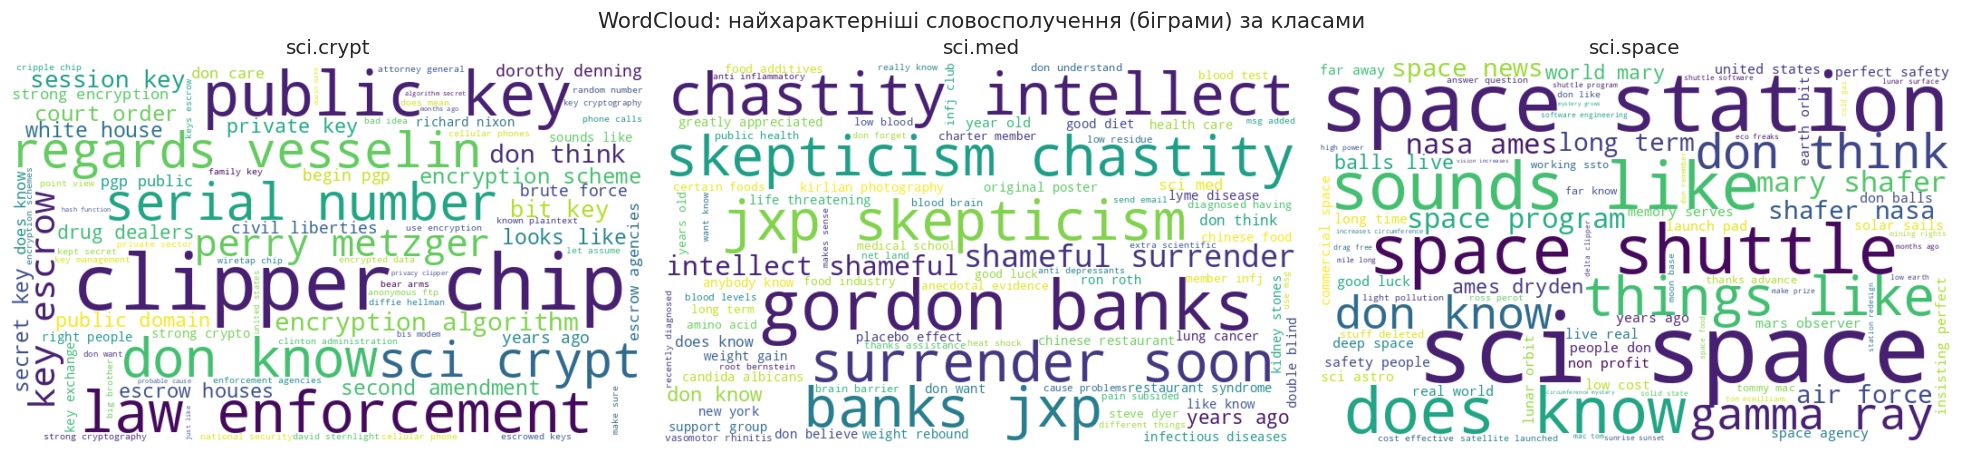

Топ-10 біграм:


,sci.crypt,sci.med,sci.space
1,clipper chip,gordon banks,sci space
2,public key,chastity intellect,space station
3,law enforcement,skepticism chastity,space shuttle
4,don know,banks jxp,sounds like
5,serial number,jxp skepticism,does know
6,regards vesselin,surrender soon,things like
7,sci crypt,shameful surrender,don think
8,perry metzger,intellect shameful,gamma ray
9,key escrow,don know,don know
10,encryption algorithm,years ago,mary shafer


In [24]:
top_bi = class_wordclouds((2, 2), "WordCloud: найхарактерніші словосполучення (біграми) за класами")
print("Топ-10 біграм:")
top_bi

### Пояснення хмар (орієнтир)
- Для кожного класу домінують слова **його предметної області**: для `sci.crypt` — терміни шифрування й безпеки (ключі, алгоритми, шифри), для `sci.med` — медичні терміни (лікування, пацієнти, хвороби), для `sci.space` — космічна лексика (орбіта, місія, запуск). Саме це й дає класифікатору змогу розрізняти тексти.
- **Біграми** (словосполучення) конкретніші й інформативніші за окремі слова, бо передають усталені терміни. Але вони розрідженіші — тому в хмарі їх менше й вони дрібніші.
- Якщо в хмарі є «чужі» слова (наприклад, з іншого класу) — це ознака лексичного перетину тем: саме там модель надалі помилятиметься (перевіримо за confusion matrix).

## 3.2 TF-IDF-векторизація та класифікація

### Ідея TF-IDF
Перетворюємо кожен текст на числовий вектор довжиною в розмір словника. Значення для слова *t* у документі *d*:

**TF-IDF(t, d) = TF(t, d) × IDF(t)**, де **TF** — наскільки слово часте в документі, **IDF = log(N / df)** — наскільки слово *рідкісне* по корпусу (df — кількість документів зі словом). Слова, що є всюди, отримують малу вагу; слова-маркери теми — велику. Вектори нормуються (L2).

### Параметри `TfidfVectorizer`
`ngram_range=(1,2)` — слова та біграми; `min_df=3` — ігноруємо слова, що трапляються менш ніж у 3 документах (шум і одруківки); `max_df=0.5` — відкидаємо надто поширені; `sublinear_tf=True` — гасимо вплив дуже високих частот (1 + log TF).

### Моделі
Порівнюємо три класичні для текстів моделі: **логістична регресія**, **Multinomial Naive Bayes**, **LinearSVC**. **Векторизатор навчається лише на train** (словник і IDF береться з train), до test він лише застосовується — інакше витік.

In [25]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.5, sublinear_tf=True, max_features=50_000)
Xtf_tr = tfidf.fit_transform(Xtxt_tr)          # fit тільки на train
Xtf_te = tfidf.transform(Xtxt_te)
print("Матриця TF-IDF train:", Xtf_tr.shape, "| розрідженість:", f"{1 - Xtf_tr.nnz / np.prod(Xtf_tr.shape):.2%}")

models = {"Logistic Regression": LogisticRegression(max_iter=1000, C=10, random_state=RANDOM_STATE),
          "Multinomial NB": MultinomialNB(alpha=0.1),
          "LinearSVC": LinearSVC(C=1.0, random_state=RANDOM_STATE)}
rows, preds = {}, {}
for name, m in models.items():
    t0 = time.perf_counter(); m.fit(Xtf_tr, ytxt_tr); dt = time.perf_counter() - t0
    p = m.predict(Xtf_te); preds[name] = p
    rows[name] = {"Accuracy": accuracy_score(ytxt_te, p), "F1-macro": f1_score(ytxt_te, p, average="macro"), "Час fit, с": dt}
text_res = pd.DataFrame(rows).T.round(4)
text_res

Матриця TF-IDF train: (1723, 12428) | розрідженість: 99.37%


,Accuracy,F1-macro,"Час fit, с"
Logistic Regression,0.9020,0.9024,1.5023
Multinomial NB,0.9261,0.9261,0.0164
LinearSVC,0.8985,0.8988,0.1004


Найкраща модель за F1-macro: Multinomial NB

              precision    recall  f1-score   support

   sci.crypt      0.944     0.911     0.927       372
     sci.med      0.928     0.928     0.928       376
   sci.space      0.907     0.939     0.923       375

    accuracy                          0.926      1123
   macro avg      0.927     0.926     0.926      1123
weighted avg      0.927     0.926     0.926      1123



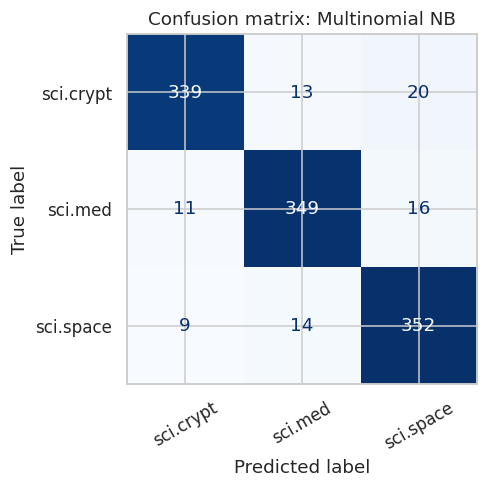

In [26]:
best_name = text_res["F1-macro"].idxmax()
print(f"Найкраща модель за F1-macro: {best_name}\n")
print(classification_report(ytxt_te, preds[best_name], target_names=cls_txt, digits=3))

fig, ax = plt.subplots(figsize=(5.2, 4.6))
ConfusionMatrixDisplay.from_predictions(ytxt_te, preds[best_name], display_labels=cls_txt,
                                        cmap="Blues", ax=ax, xticks_rotation=30, colorbar=False)
ax.set_title(f"Confusion matrix: {best_name}"); plt.tight_layout(); plt.show()

### Як читати метрики
- **Precision** (точність) класу: з усього, що модель віднесла до класу, скільки справді належить йому. **Recall** (повнота): скільки реальних документів класу модель знайшла. **F1** — їх гармонійне середнє. **Support** — кількість документів класу в test.
- **Confusion matrix:** рядок — справжній клас, стовпець — передбачений; діагональ — правильні відповіді, поза діагоналлю — конкретні плутанини (які теми модель сплутала між собою).
- **Accuracy** тут інформативна, бо класи майже збалансовані; **F1-macro** додатково гарантує, що жоден клас не «провалений».

In [27]:
# Які слова вирішують питання: найбільші коефіцієнти логістичної регресії для кожного класу
lr = models["Logistic Regression"]
vocab = np.array(tfidf.get_feature_names_out())
top = {name: list(vocab[np.argsort(lr.coef_[i])[::-1][:10]]) for i, name in enumerate(cls_txt)}
print("Топ-10 ознак (слів/біграм), що найсильніше «голосують» за клас:")
pd.DataFrame(top, index=range(1, 11))

Топ-10 ознак (слів/біграм), що найсильніше «голосують» за клас:


,sci.crypt,sci.med,sci.space
1,key,medical,space
2,encryption,doctor,orbit
3,clipper,msg,earth
4,nsa,disease,nasa
5,government,health,launch
6,chip,pain,moon
7,keys,treatment,spacecraft
8,security,cancer,shuttle
9,clinton,effects,allen
10,phone,patients,solar


In [28]:
# Перевірка на нових реченнях
samples = ["The new encryption algorithm uses a 256-bit key and public key cryptography.",
           "The patient was prescribed antibiotics for the infection and symptoms of the disease.",
           "NASA plans to launch the satellite into orbit around the moon next year."]
pred = lr.predict(tfidf.transform([clean_text(s) for s in samples]))
for s, p in zip(samples, pred):
    print(f"[{cls_txt[p]:10s}] {s}")

[sci.crypt ] The new encryption algorithm uses a 256-bit key and public key cryptography.
[sci.med   ] The patient was prescribed antibiotics for the infection and symptoms of the disease.
[sci.space ] NASA plans to launch the satellite into orbit around the moon next year.


In [29]:
print("ВИСНОВОК (Розділ 3):")
r = text_res.loc[best_name]
print(f" - Найкраща модель: {best_name}: accuracy = {r['Accuracy']:.3f}, F1-macro = {r['F1-macro']:.3f}.")
print(f" - Різниця між моделями: F1-macro від {text_res['F1-macro'].min():.3f} до {text_res['F1-macro'].max():.3f}.")
cm = confusion_matrix(ytxt_te, preds[best_name]).astype(float)
np.fill_diagonal(cm, 0)
i, j = np.unravel_index(cm.argmax(), cm.shape)
if cm.max() > 0:
    print(f" - Найчастіша помилка: справжній '{cls_txt[i]}' -> передбачений '{cls_txt[j]}' ({int(cm[i, j])} випадків).")
else:
    print(" - Помилок на test немає.")

ВИСНОВОК (Розділ 3):
 - Найкраща модель: Multinomial NB: accuracy = 0.926, F1-macro = 0.926.
 - Різниця між моделями: F1-macro від 0.899 до 0.926.
 - Найчастіша помилка: справжній 'sci.crypt' -> передбачений 'sci.space' (20 випадків).


### Висновки до Розділу 3
Лінійні моделі на TF-IDF-ознаках — сильний базовий варіант для класифікації текстів: вони швидкі, добре працюють із розрідженими високовимірними даними та **інтерпретовні** (видно, які слова «голосують» за клас). Якість обмежена там, де теми лексично перетинаються (див. confusion matrix). Можливі напрями покращення: підбір гіперпараметрів (`GridSearchCV`), лематизація, більше класів/даних, контекстні ембединги (BERT) замість «мішка слів».

# Загальні висновки

1. **PCA** зменшує кількість ознак (скільки саме — див. висновок у п. 1.1), зберігаючи більшу частину інформації; вплив на якість і час залежить від кореляції ознак та типу моделі: для дерев/лісів виграш у швидкості помірний, для методів на відстанях (kNN) — відчутніший. Ціна — втрата інтерпретовності ознак.
2. **t-SNE** показує, чи розділимі класи у просторі ознак; це візуальний інструмент, а не метрика, і його картинки залежать від perplexity. Висновки з відстаней між групами робити не можна.
3. **K-Means** знаходить *геометричні* групи без міток. Збіг із класами оцінюється метриками (ARI, NMI, homogeneity/completeness): **кластер ≠ клас**, тому відсутність повного збігу — не помилка, а результат, який треба пояснити.
4. **Тексти:** передобробка → TF-IDF → лінійний класифікатор дає високу якість на тематичному корпусі; WordCloud на основі TF-IDF наочно показує лексику класів і узгоджується з метриками.

---